# 02 · Análise Exploratória de Dados (EDA)

Roda em cima de `data/processed/features_farl.parquet` (gerado no notebook 01). Não precisa de GPU.

Pode rodar no Colab (o bloco abaixo pega o arquivo do Drive) ou localmente no VS Code.
Todas as figuras são salvas em `reports/figures/` para irem direto ao relatório.

In [1]:
import os, sys
EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_URL = "https://github.com/Rodrigotorres1/veridade.git"
    if not os.path.exists("/content/repo"):
        os.system(f"git clone -q {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    os.makedirs("data/processed", exist_ok=True)
    os.system("cp /content/drive/MyDrive/projeto-ml/processed/features_farl.parquet data/processed/")
else:
    os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import (FEATURES_FILE, EMB_COLS, LIMIARES_CONTRIBUICAO, LIMIAR_PRINCIPAL, ROOT)

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
PALETA = {"UTKFace": "#2E6F9E", "FG-NET": "#D9822B"}

def salvar(nome):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{nome}.png", dpi=200, bbox_inches="tight")
    plt.show()

df = pd.read_parquet(FEATURES_FILE)
meta = df.drop(columns=EMB_COLS)
E = df[EMB_COLS].to_numpy()
print(df.shape)

Mounted at /content/drive
(24688, 520)


## 1. Visão geral e estatísticas descritivas

In [2]:
resumo = meta.groupby("dataset").agg(
    imagens=("idade", "size"),
    idade_media=("idade", "mean"), idade_mediana=("idade", "median"),
    idade_desvio=("idade", "std"), idade_min=("idade", "min"), idade_max=("idade", "max"),
    pct_menor_18=("idade", lambda s: 100 * (s < 18).mean()),
).round(2)
resumo

,imagens,idade_media,idade_mediana,idade_desvio,idade_min,idade_max,pct_menor_18
dataset,,,,,,,
FG-NET,1002,15.84,13.0,12.87,0,69,63.87
UTKFace,23686,33.24,29.0,19.77,1,101,17.87


In [3]:
print("Imagens por split:")
print(pd.crosstab(meta["dataset"], meta["split"], margins=True))
print()
print("Sujeitos distintos no FG-NET:", meta.loc[meta.dataset == "FG-NET", "sujeito"].nunique())
print("Imagens por sujeito no FG-NET (média):",
      round(meta[meta.dataset == "FG-NET"].groupby("sujeito").size().mean(), 1))

Imagens por split:
split    test  test_externo  train   val    All
dataset                                        
FG-NET      0          1002      0     0   1002
UTKFace  3553             0  16580  3553  23686
All      3553          1002  16580  3553  24688

Sujeitos distintos no FG-NET: 82
Imagens por sujeito no FG-NET (média): 12.2


## 2. Qualidade dos dados

Checagens que justificam o tratamento:
- **valores ausentes** nos rótulos e nos embeddings
- **norma dos embeddings** (devem ser ~1, pois aplicamos normalização L2)
- **imagens duplicadas** (o UTKFace tem duplicatas conhecidas; a mesma foto em treino e teste inflaria as métricas)
- **rostos não detectados** no FG-NET (recorte central usado como alternativa)

In [4]:
print("Ausentes em idade:", meta["idade"].isna().sum())
print("Ausentes nos embeddings:", int(np.isnan(E).sum()))
normas = np.linalg.norm(E, axis=1)
print(f"Norma dos embeddings: min={normas.min():.4f} max={normas.max():.4f}")
print("FG-NET sem rosto detectado:", int((~meta.loc[meta.dataset == 'FG-NET', 'rosto_detectado'].astype(bool)).sum()))

# Duplicatas: embeddings praticamente idênticos (arredondados) = mesma imagem
chave = pd.util.hash_pandas_object(pd.DataFrame(E.round(4)), index=False)
dup = chave.duplicated(keep=False)
meta["duplicada"] = dup.values
print(f"\nImagens em grupos duplicados: {dup.sum()}")
grupos = meta[dup].assign(chave=chave[dup].values).groupby("chave")["split"].agg(lambda s: tuple(sorted(set(s))))
vazamento = grupos[grupos.map(len) > 1]
print(f"Grupos de duplicatas espalhados em splits diferentes (vazamento): {len(vazamento)}")

Ausentes em idade: 0
Ausentes nos embeddings: 0
Norma dos embeddings: min=1.0000 max=1.0000
FG-NET sem rosto detectado: 3

Imagens em grupos duplicados: 763
Grupos de duplicatas espalhados em splits diferentes (vazamento): 185


**Decisão de tratamento:** remover duplicatas mantendo uma cópia por grupo, para evitar que a mesma foto apareça
em treino e teste. O resultado é salvo em `features_farl_limpo.parquet`, que passa a ser a base dos próximos notebooks.

In [5]:
antes = len(df)
manter = ~chave.duplicated(keep="first").values
df_limpo = df[manter].reset_index(drop=True)
meta = meta[manter].reset_index(drop=True)
E = E[manter]
df_limpo.to_parquet(FEATURES_FILE.with_name("features_farl_limpo.parquet"), index=False)
print(f"Removidas {antes - len(df_limpo)} duplicatas. Base final: {len(df_limpo)} imagens")

Removidas 389 duplicatas. Base final: 24299 imagens


## 3. Visualizações

### Fig. 1 · Distribuição de idade por dataset

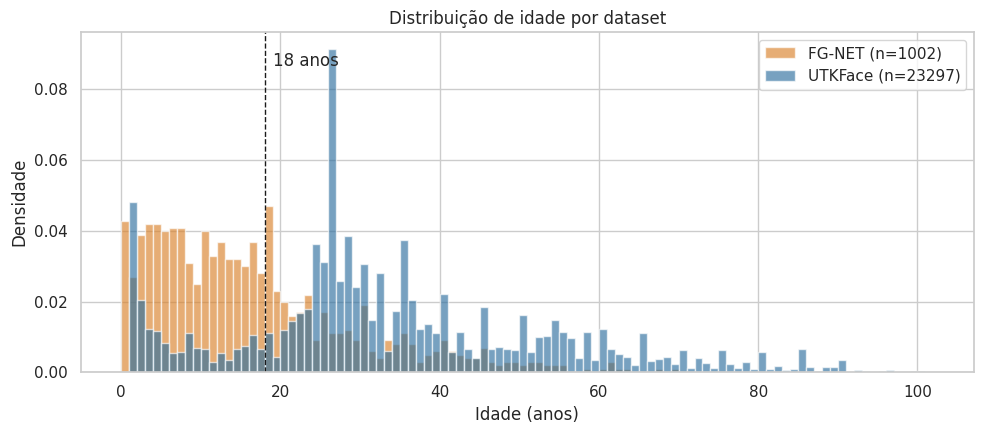

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for nome, g in meta.groupby("dataset"):
    ax.hist(g["idade"], bins=range(0, 103), alpha=.65, density=True, label=f"{nome} (n={len(g)})", color=PALETA[nome])
ax.axvline(LIMIAR_PRINCIPAL, ls="--", c="k", lw=1); ax.text(LIMIAR_PRINCIPAL + 1, ax.get_ylim()[1] * .9, "18 anos")
ax.set(xlabel="Idade (anos)", ylabel="Densidade", title="Distribuição de idade por dataset")
ax.legend(); salvar("fig1_distribuicao_idade")

**Interpretação:** O UTKFace concentra adultos jovens (mediana de 29 anos), com um pico em bebês de 1 ano e um pico anormal aos 26 anos (cerca de 9% de densidade, muito acima das idades vizinhas). Também há acúmulos em múltiplos de 5 (30, 35, 40, 45...), o que indica rótulos arredondados ou estimados: ruído de rótulo que limita o erro mínimo alcançável. O FG-NET, ao contrário, é dominado por crianças e adolescentes, com distribuição quase uniforme de 0 a 18 anos. Por isso ele é um bom teste externo para a faixa que importa ao ECA Digital.

### Fig. 2 · Proporção de menores em cada limiar legal

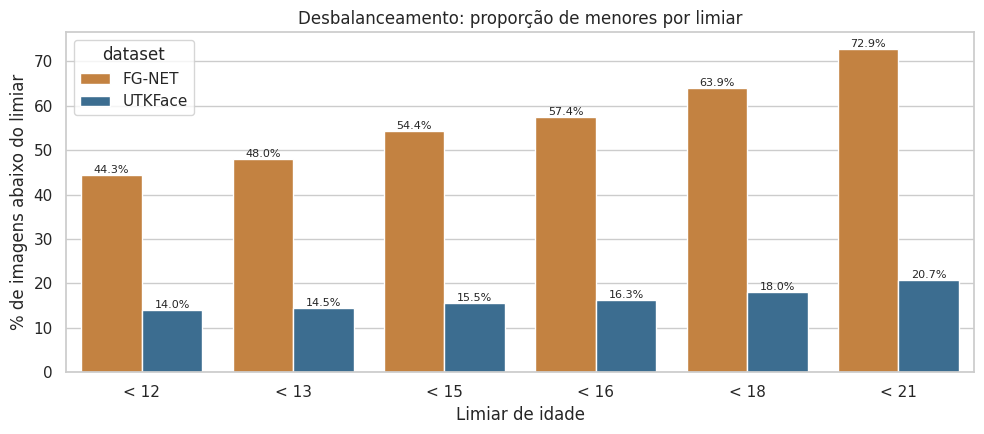

In [7]:
linhas = []
for nome, g in meta.groupby("dataset"):
    for t in LIMIARES_CONTRIBUICAO:
        linhas.append({"dataset": nome, "limiar": f"< {t}", "pct": 100 * (g["idade"] < t).mean()})
prop = pd.DataFrame(linhas)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(prop, x="limiar", y="pct", hue="dataset", palette=PALETA, ax=ax)
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%", fontsize=8)
ax.set(xlabel="Limiar de idade", ylabel="% de imagens abaixo do limiar",
       title="Desbalanceamento: proporção de menores por limiar")
salvar("fig2_proporcao_menores")

**Interpretação:** No UTKFace, a proporção de positivos varia de 14,0% (< 12) a 20,7% (< 21): todas as tarefas binárias são desbalanceadas. O dado mais importante é que entre os limiares 12 e 18 a proporção sobe só 4 pontos percentuais, ou seja, adolescentes de 12 a 17 anos são apenas cerca de 4% do dataset. Isso justifica a validação estratificada, o uso de F2 e recall como métricas principais (acurácia seria enganosa: um modelo que chama todos de adulto acertaria 82%) e antecipa que os limiares 13, 15 e 16 serão os mais difíceis. No FG-NET a situação se inverte (63,9% são menores de 18).

### Fig. 3 · Zona de ambiguidade perto dos limiares (10 a 25 anos)

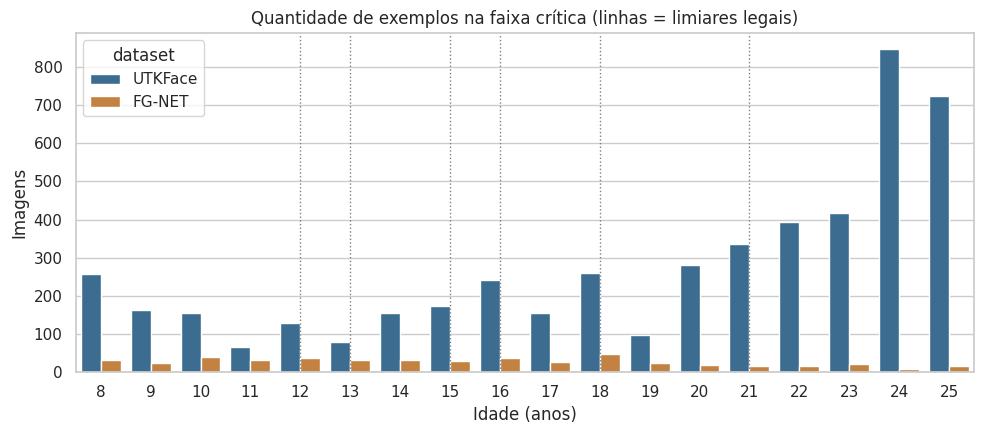

In [8]:
zona = meta[(meta.idade >= 8) & (meta.idade <= 25)]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.countplot(zona, x="idade", hue="dataset", palette=PALETA, ax=ax)
for t in [12, 13, 15, 16, 18, 21]:
    ax.axvline(t - 8, ls=":", c="gray", lw=1)
ax.set(xlabel="Idade (anos)", ylabel="Imagens", title="Quantidade de exemplos na faixa crítica (linhas = limiares legais)")
salvar("fig3_zona_critica")

**Interpretação:** A faixa de 11 a 19 anos tem entre 65 e 260 imagens por idade no UTKFace, contra 845 aos 24 anos: adolescentes são até 10 vezes menos representados que adultos jovens. As idades 11, 13 e 19 são especialmente raras (menos de 100 imagens cada). Como os limiares legais (12, 13, 15, 16, 18) caem exatamente nessa região, a fronteira de decisão será aprendida com poucos exemplos, o que motiva as técnicas do artigo (reamostragem balanceada por idade e cabeças binárias dedicadas a cada limiar).

### Fig. 4 · Distribuição de idade por split (checagem da estratificação)

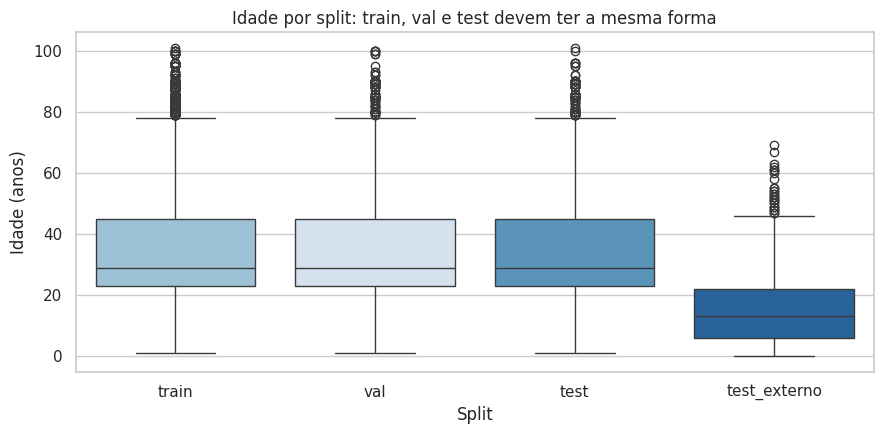

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ordem = ["train", "val", "test", "test_externo"]
sns.boxplot(meta, x="split", y="idade", order=ordem, hue="split", palette="Blues", legend=False, ax=ax)
ax.set(xlabel="Split", ylabel="Idade (anos)", title="Idade por split: train, val e test devem ter a mesma forma")
salvar("fig4_idade_por_split")

**Interpretação:** Train, val e test têm distribuições praticamente idênticas (mediana de 29 anos, intervalo interquartil de 23 a 45), confirmando que a estratificação por faixa etária funcionou e que a avaliação no teste é representativa do treino. O test_externo (FG-NET) tem mediana de 13 anos e intervalo de 6 a 22, propositalmente diferente: mede se o modelo generaliza para outra fonte de imagens e para uma população majoritariamente menor de idade.

### Fig. 5 · Composição demográfica do UTKFace (risco de viés)

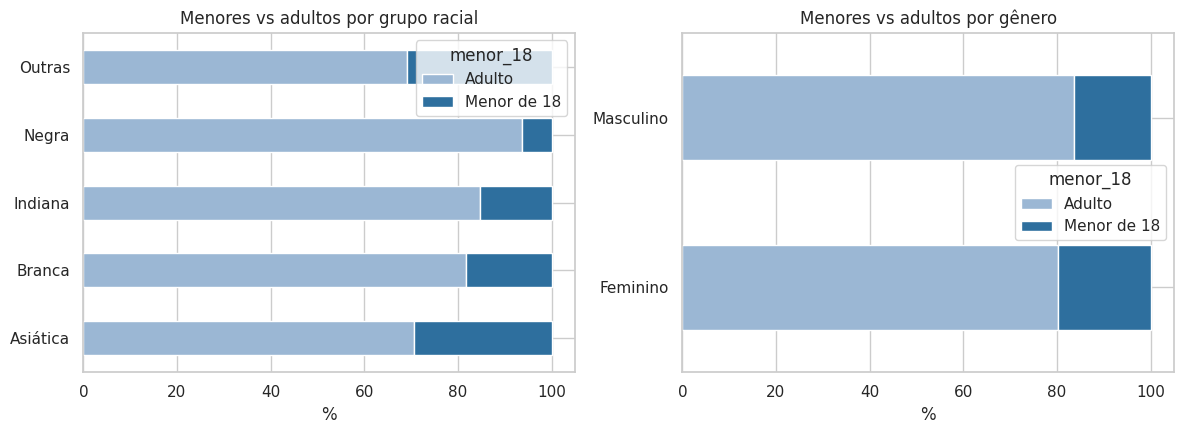

raca_nome
Branca      42.7
Negra       19.1
Indiana     16.7
Asiática    14.5
Outras       7.0
Name: proportion, dtype: float64


In [10]:
utk = meta[meta.dataset == "UTKFace"].copy()
utk["raca_nome"] = utk["raca"].map({0: "Branca", 1: "Negra", 2: "Asiática", 3: "Indiana", 4: "Outras"})
utk["genero_nome"] = utk["genero"].map({0: "Masculino", 1: "Feminino"})
utk["menor_18"] = np.where(utk["idade"] < 18, "Menor de 18", "Adulto")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
pd.crosstab(utk["raca_nome"], utk["menor_18"], normalize="index").mul(100).plot.barh(stacked=True, ax=axes[0], color=["#9BB7D4", "#2E6F9E"])
axes[0].set(xlabel="%", ylabel="", title="Menores vs adultos por grupo racial")
pd.crosstab(utk["genero_nome"], utk["menor_18"], normalize="index").mul(100).plot.barh(stacked=True, ax=axes[1], color=["#9BB7D4", "#2E6F9E"])
axes[1].set(xlabel="%", ylabel="", title="Menores vs adultos por gênero")
salvar("fig5_demografia")
print(utk["raca_nome"].value_counts(normalize=True).mul(100).round(1))

**Interpretação:** O UTKFace é dominado por pessoas brancas (42,7%), e a proporção de menores varia muito entre grupos: cerca de 30% entre asiáticos e "outras", cerca de 18% entre brancos e apenas cerca de 6% entre negros. Na prática, menores negros representam aproximadamente 1% do dataset, então o modelo terá muito menos exemplos para aprender a reconhecer crianças e adolescentes negros. Esse é um risco concreto de viés: um sistema de verificação de idade poderia errar mais para esse grupo. Na fase de modelagem, avaliaremos a taxa de falso adulto por grupo. Entre gêneros a diferença é pequena (cerca de 20% de menores no feminino e 16% no masculino).

### Fig. 6 · Embeddings em 2D (PCA) coloridos por idade e por dataset

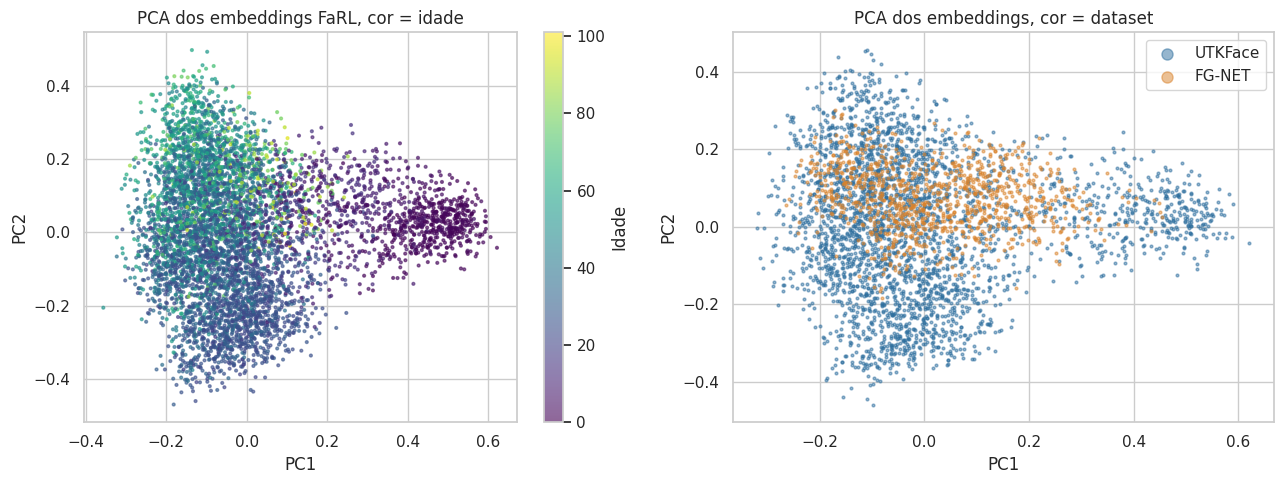

In [11]:
from sklearn.decomposition import PCA
pca = PCA(n_components=50, random_state=42).fit(E[meta.split == "train"])
Z = pca.transform(E)

rng = np.random.default_rng(0)
amostra = rng.choice(len(Z), size=min(6000, len(Z)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc = axes[0].scatter(Z[amostra, 0], Z[amostra, 1], c=meta.idade.values[amostra], cmap="viridis", s=4, alpha=.6)
plt.colorbar(sc, ax=axes[0], label="Idade")
axes[0].set(xlabel="PC1", ylabel="PC2", title="PCA dos embeddings FaRL, cor = idade")
for nome in ["UTKFace", "FG-NET"]:
    m = (meta.dataset.values == nome)
    idx = np.where(m)[0] if nome == "FG-NET" else rng.choice(np.where(m)[0], min(3000, m.sum()), replace=False)
    axes[1].scatter(Z[idx, 0], Z[idx, 1], s=4, alpha=.5, label=nome, c=PALETA[nome])
axes[1].set(xlabel="PC1", ylabel="PC2", title="PCA dos embeddings, cor = dataset"); axes[1].legend(markerscale=4)
salvar("fig6_pca_embeddings")

**Interpretação:** No painel da esquerda há um gradiente claro ao longo do PC1: crianças pequenas formam um grupo compacto à direita (PC1 > 0,3) e adultos ficam à esquerda, sem nenhum treino envolvido. Isso confirma que o FaRL já codifica a idade, o que explica o MAE de 5,4 anos de uma regressão linear simples. No painel da direita, o FG-NET fica dentro da nuvem do UTKFace, concentrado na faixa central, sem formar um grupo separado. Isso sugere que a mudança de domínio existe, mas é moderada: parte do MAE maior no FG-NET (9,1 anos) deve vir da diferença na distribuição de idades, já que a regressão linear tende a puxar previsões para a média do treino (29 anos) e superestimar crianças. Essa hipótese será verificada com o erro por faixa etária.

### Fig. 7 · Quantas dimensões os embeddings realmente usam

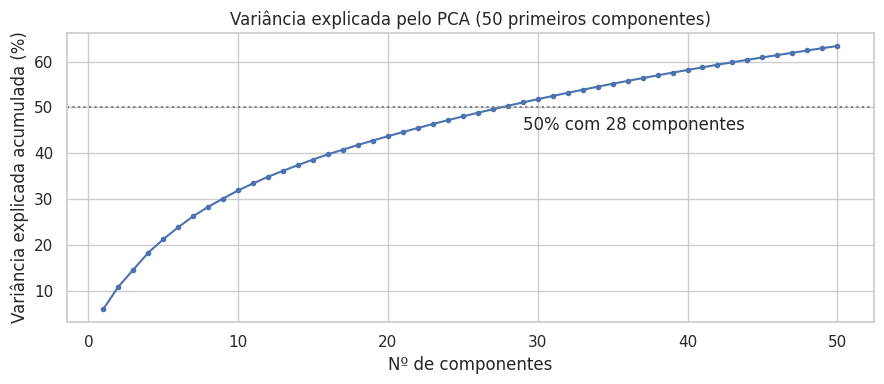

In [12]:
acum = np.cumsum(pca.explained_variance_ratio_) * 100
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, 51), acum, marker="o", ms=3)
for alvo in [50, 80]:
    k = int(np.argmax(acum >= alvo)) + 1 if (acum >= alvo).any() else None
    if k: ax.axhline(alvo, ls=":", c="gray"); ax.text(k + 1, alvo - 5, f"{alvo}% com {k} componentes")
ax.set(xlabel="Nº de componentes", ylabel="Variância explicada acumulada (%)", title="Variância explicada pelo PCA (50 primeiros componentes)")
salvar("fig7_variancia_pca")

**Interpretação:** A variância está bem espalhada: são necessários 28 componentes para explicar 50% e 50 componentes explicam apenas cerca de 63%. Não existe uma estrutura de poucas dimensões, então reduzir agressivamente com PCA tende a perder informação. Mesmo assim, modelos sensíveis à dimensionalidade, como KNN e Árvore de Decisão, podem se beneficiar de uma redução moderada; o número de componentes será tratado como hiperparâmetro na otimização.

### Fig. 8 · Separabilidade menor vs adulto ao longo do PC mais relacionado com idade

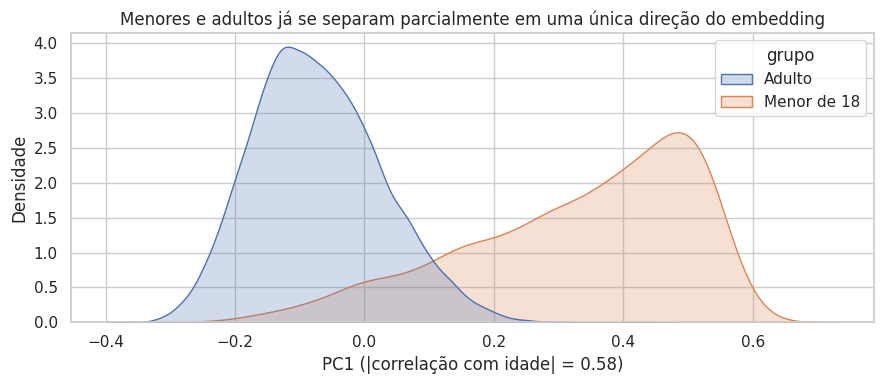

In [13]:
corr = [abs(np.corrcoef(Z[:, i], meta.idade)[0, 1]) for i in range(10)]
pc = int(np.argmax(corr))
plot = pd.DataFrame({"valor": Z[:, pc], "grupo": np.where(meta.idade < 18, "Menor de 18", "Adulto"), "dataset": meta.dataset})
fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(plot[plot.dataset == "UTKFace"], x="valor", hue="grupo", fill=True, common_norm=False, ax=ax)
ax.set(xlabel=f"PC{pc + 1} (|correlação com idade| = {corr[pc]:.2f})", ylabel="Densidade",
       title="Menores e adultos já se separam parcialmente em uma única direção do embedding")
salvar("fig8_separabilidade")

**Interpretação:** Uma única direção do embedding (PC1, correlação de 0,58 com a idade) já separa boa parte dos menores dos adultos: os picos das duas curvas estão bem afastados (cerca de -0,12 contra 0,48). Porém, a curva dos menores tem uma cauda longa à esquerda que se sobrepõe aos adultos entre -0,1 e 0,15; essa região provavelmente corresponde aos adolescentes, que são justamente os casos críticos. Separar esses casos exige combinar as 512 dimensões, o que justifica o uso de modelos não lineares.

## 4. Resumo das decisões de tratamento

| Decisão | Motivo |
|---|---|
| Remover idades > 101 | O artigo usa 102 classes (0 a 101) |
| Ignorar arquivos com nome fora do padrão | Sem rótulo confiável |
| Recortar rosto no FG-NET (MTCNN) | O FaRL espera rosto recortado, como no UTKFace |
| Normalização L2 dos embeddings | Igual ao artigo ("normalized and projected output") |
| Remover duplicatas | Evitar vazamento entre treino e teste |
| Split estratificado por faixa etária, semente fixa | Mesma distribuição em train/val/test e reprodutibilidade |
| FG-NET só como teste externo | Medir generalização em outro domínio, rico em menores |
| Não usar acurácia como métrica principal | Classes desbalanceadas (Fig. 2) |